# Лабораторна робота 4. Задача класифікації

**Виконала:** Сєднєва Уляна, група 4-10
**Варіант:** 19
**Репозиторій GitHub:** https://github.com/UlyanaSedneva/LB4.git

In [69]:
# Підключення бібліотек
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)

pd.set_option('display.float_format', lambda x: f'{x:.3f}')
pd.set_option('display.max_columns', 35)
RANDOM_STATE = 19   # варіант 19 - для відтворюваності результатів

---
# Завдання 1. Breast Cancer Dataset

## 1. Завантаження вбудованого датасету `load_breast_cancer`

In [70]:
bc = load_breast_cancer(as_frame=True)
cancer = bc.frame.copy()

# Перевіряємо кодування класів безпосередньо в бібліотеці
print('Класи:', dict(enumerate(bc.target_names)))

Класи: {0: np.str_('malignant'), 1: np.str_('benign')}


> **Увага щодо кодування класів.** В описі датасету в методичці вказано 0 — доброякісна, 1 — злоякісна пухлина. Але бібліотека sklearn кодує класи навпаки: **0 — malignant (злоякісна), 1 — benign (доброякісна)**, що видно з виводу вище. Далі в роботі використано справжнє кодування бібліотеки.

## 2. Попередній аналіз даних

In [71]:
# 2.1. Перші кілька рядків
cancer.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.990,10.380,122.800,1001.000,0.118,0.278,0.300,0.147,0.242,0.079,1.095,0.905,8.589,153.400,0.006,0.049,0.054,0.016,0.030,0.006,25.380,17.330,184.600,2019.000,0.162,0.666,0.712,0.265,0.460,0.119,0
1,20.570,17.770,132.900,1326.000,0.085,0.079,0.087,0.070,0.181,0.057,0.543,0.734,3.398,74.080,0.005,0.013,0.019,0.013,0.014,0.004,24.990,23.410,158.800,1956.000,0.124,0.187,0.242,0.186,0.275,0.089,0
2,19.690,21.250,130.000,1203.000,0.110,0.160,0.197,0.128,0.207,0.060,0.746,0.787,4.585,94.030,0.006,0.040,0.038,0.021,0.022,0.005,23.570,25.530,152.500,1709.000,0.144,0.424,0.450,0.243,0.361,0.088,0
3,11.420,20.380,77.580,386.100,0.142,0.284,0.241,0.105,0.260,0.097,0.496,1.156,3.445,27.230,0.009,0.075,0.057,0.019,0.060,0.009,14.910,26.500,98.870,567.700,0.210,0.866,0.687,0.258,0.664,0.173,0
4,20.290,14.340,135.100,1297.000,0.100,0.133,0.198,0.104,0.181,0.059,0.757,0.781,5.438,94.440,0.011,0.025,0.057,0.019,0.018,0.005,22.540,16.670,152.200,1575.000,0.137,0.205,0.400,0.163,0.236,0.077,0


In [72]:
# 2.2. Назви стовпців та типи даних
print('Назви стовпців:', list(cancer.columns), '\n')
print(cancer.dtypes.value_counts())
cancer.info()

Назви стовпців: ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension', 'target'] 

float64    30
int64       1
Name: count, dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter  

In [73]:
# 2.3. Пропущені значення
print('Кількість пропусків у всьому датасеті:', cancer.isna().sum().sum())
print('Кількість дублікатів:', cancer.duplicated().sum())

Кількість пропусків у всьому датасеті: 0
Кількість дублікатів: 0


In [74]:
# 2.4. Розмір даних і баланс класів
print('Розмір датасету (зразки, стовпці):', cancer.shape)
print('Кількість ознак:', cancer.shape[1] - 1)
counts = cancer['target'].map({0: 'malignant (0)', 1: 'benign (1)'}).value_counts()
print('\nРозподіл класів:')
print(pd.DataFrame({'Кількість': counts, 'Частка, %': (counts / len(cancer) * 100).round(1)}))

Розмір датасету (зразки, стовпці): (569, 31)
Кількість ознак: 30

Розподіл класів:
               Кількість  Частка, %
target                             
benign (1)           357     62.700
malignant (0)        212     37.300


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension
count,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000
mean,14.127,19.290,91.969,654.889,0.096,0.104,0.089,0.049,0.181,0.063
std,3.524,4.301,24.299,351.914,0.014,0.053,0.080,0.039,0.027,0.007
min,6.981,9.710,43.790,143.500,0.053,0.019,0.000,0.000,0.106,0.050
25%,11.700,16.170,75.170,420.300,0.086,0.065,0.030,0.020,0.162,0.058
50%,13.370,18.840,86.240,551.100,0.096,0.093,0.062,0.034,0.179,0.062
75%,15.780,21.800,104.100,782.700,0.105,0.130,0.131,0.074,0.196,0.066
max,28.110,39.280,188.500,2501.000,0.163,0.345,0.427,0.201,0.304,0.097


Ознаки з найсильнішим зв'язком із класом (|r|):
worst concave points   -0.794
worst perimeter        -0.783
mean concave points    -0.777
worst radius           -0.776
mean perimeter         -0.743
worst area             -0.734
mean radius            -0.730
mean area              -0.709
mean concavity         -0.696
worst concavity        -0.660
Name: target, dtype: float64


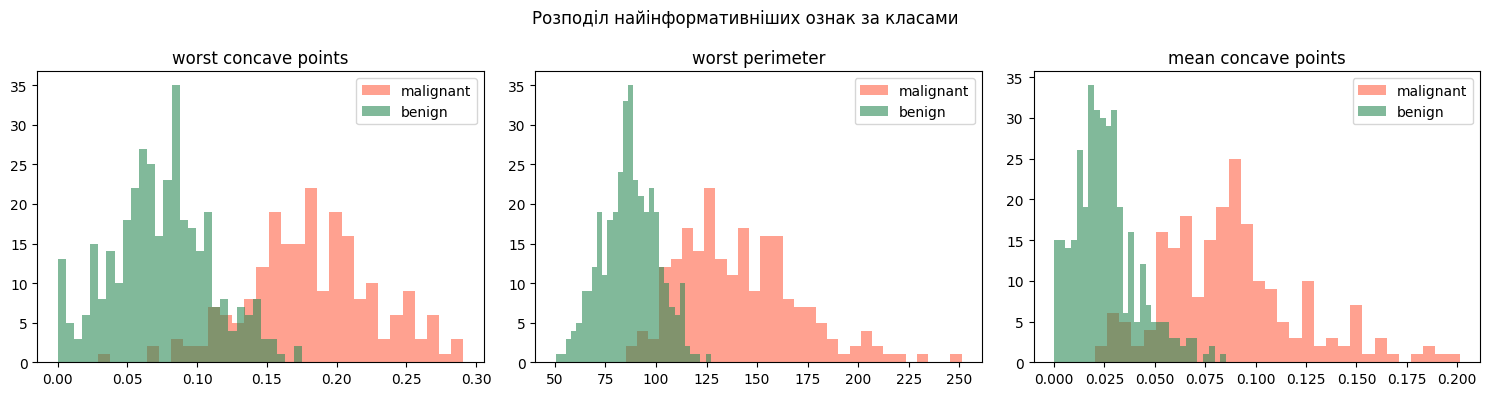

In [75]:
# Описова статистика перших 10 ознак (середні значення) і зв'язок ознак з класом
display(cancer.iloc[:, :10].describe())

corr_bc = cancer.corr()['target'].drop('target').sort_values(key=abs, ascending=False)
print('Ознаки з найсильнішим зв\'язком із класом (|r|):')
print(corr_bc.head(10))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, corr_bc.index[:3]):
    for cls, name, color in [(0, 'malignant', 'tomato'), (1, 'benign', 'seagreen')]:
        ax.hist(cancer.loc[cancer['target'] == cls, col], bins=30, alpha=0.6, label=name, color=color)
    ax.set_title(col); ax.legend()
plt.suptitle('Розподіл найінформативніших ознак за класами')
plt.tight_layout(); plt.show()

## 3. Побудова і налаштування моделей

In [76]:
# 3.1. Поділ на навчальний (80 %) і тестовий (20 %) набори
# stratify=y зберігає однакову частку класів в обох наборах
X_bc = cancer.drop(columns='target')
y_bc = cancer['target']
X_tr_bc, X_te_bc, y_tr_bc, y_te_bc = train_test_split(
    X_bc, y_bc, test_size=0.2, stratify=y_bc, random_state=RANDOM_STATE)
print('Навчальний набір:', X_tr_bc.shape, ' Тестовий набір:', X_te_bc.shape)

Навчальний набір: (455, 30)  Тестовий набір: (114, 30)


In [77]:
# 3.2-3.3. Три моделі класифікації і підбір параметрів за допомогою GridSearchCV
# Логістичній регресії потрібне масштабування ознак, тому вона в конвеєрі зі StandardScaler.
# Деревам масштабування не потрібне.
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

models_bc = {
    'Логістична регресія': (
        make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, solver='liblinear')),
        {'logisticregression__C': [0.01, 0.1, 1, 10, 100],
         'logisticregression__penalty': ['l1', 'l2']}),
    'Дерево рішень': (
        DecisionTreeClassifier(random_state=RANDOM_STATE),
        {'criterion': ['gini', 'entropy'], 'max_depth': [2, 3, 4, 5, 7, None],
         'min_samples_leaf': [1, 3, 5, 10]}),
    'Випадковий ліс': (
        RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
        {'n_estimators': [100, 300], 'max_depth': [None, 5, 10],
         'max_features': ['sqrt', 'log2']}),
}

grids_bc = {}
for name, (model, params) in models_bc.items():
    gs = GridSearchCV(model, params, cv=cv5, scoring='accuracy', n_jobs=-1)
    gs.fit(X_tr_bc, y_tr_bc)
    grids_bc[name] = gs
    print(f'{name}:\n   найкращі параметри: {gs.best_params_}\n   accuracy на крос-валідації: {gs.best_score_:.4f}')

Логістична регресія:
   найкращі параметри: {'logisticregression__C': 1, 'logisticregression__penalty': 'l2'}
   accuracy на крос-валідації: 0.9802
Дерево рішень:
   найкращі параметри: {'criterion': 'entropy', 'max_depth': 3, 'min_samples_leaf': 5}
   accuracy на крос-валідації: 0.9451
Випадковий ліс:
   найкращі параметри: {'max_depth': None, 'max_features': 'sqrt', 'n_estimators': 100}
   accuracy на крос-валідації: 0.9560


## 4. Оцінка моделей: accuracy, матриця помилок, звіт про класифікацію

Логістична регресія: accuracy = 0.9649
               precision    recall  f1-score   support

malignant (0)      0.975     0.929     0.951        42
   benign (1)      0.959     0.986     0.973        72

     accuracy                          0.965       114
    macro avg      0.967     0.957     0.962       114
 weighted avg      0.965     0.965     0.965       114

Дерево рішень: accuracy = 0.9298
               precision    recall  f1-score   support

malignant (0)      0.947     0.857     0.900        42
   benign (1)      0.921     0.972     0.946        72

     accuracy                          0.930       114
    macro avg      0.934     0.915     0.923       114
 weighted avg      0.931     0.930     0.929       114

Випадковий ліс: accuracy = 0.9912
               precision    recall  f1-score   support

malignant (0)      1.000     0.976     0.988        42
   benign (1)      0.986     1.000     0.993        72

     accuracy                          0.991       114
    ma

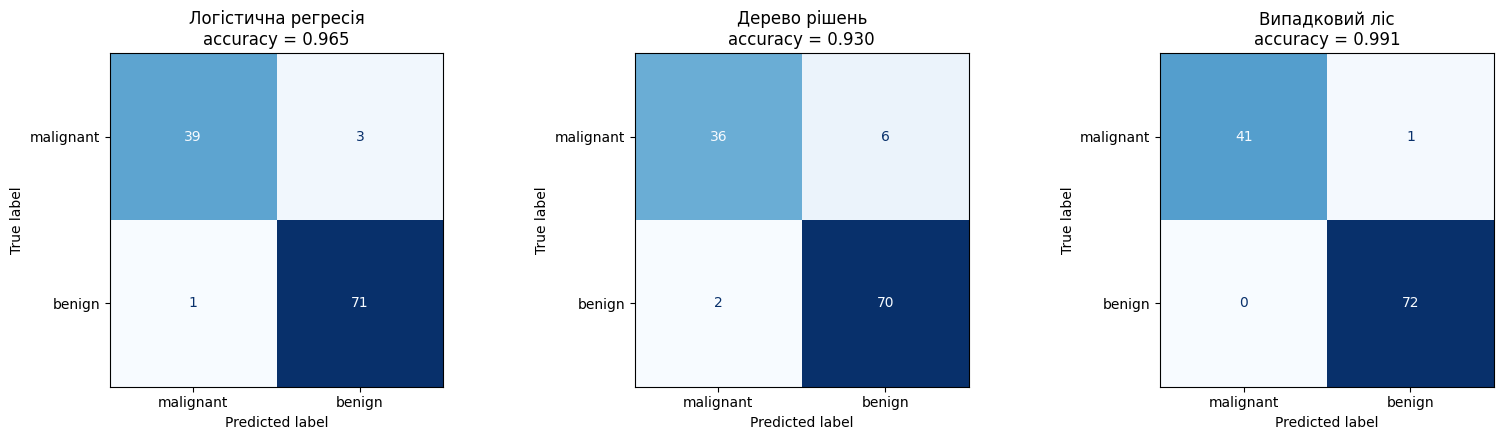

In [78]:
target_names_bc = ['malignant (0)', 'benign (1)']
preds_bc = {name: gs.best_estimator_.predict(X_te_bc) for name, gs in grids_bc.items()}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (name, pred) in zip(axes, preds_bc.items()):
    print('=' * 60)
    print(f'{name}: accuracy = {accuracy_score(y_te_bc, pred):.4f}')
    print(classification_report(y_te_bc, pred, target_names=target_names_bc, digits=3))
    ConfusionMatrixDisplay(confusion_matrix(y_te_bc, pred), display_labels=['malignant', 'benign']).plot(
        ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f'{name}\naccuracy = {accuracy_score(y_te_bc, pred):.3f}')
plt.tight_layout(); plt.show()

In [79]:
# Зведена таблиця метрик на тестовому наборі.
# Для медичної задачі особливо важливий recall злоякісного класу (0):
# пропущена злоякісна пухлина набагато небезпечніша за зайве обстеження.
def class_metrics(y_true, y_pred):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Recall_malignant': recall_score(y_true, y_pred, pos_label=0),
        'Precision_malignant': precision_score(y_true, y_pred, pos_label=0),
        'F1_macro': f1_score(y_true, y_pred, average='macro'),
        'Помилок': int((y_true != y_pred).sum()),
    }

res_bc = pd.DataFrame({n: class_metrics(y_te_bc, p) for n, p in preds_bc.items()}).T
res_bc['Помилок'] = res_bc['Помилок'].astype(int)
res_bc['CV_accuracy'] = [grids_bc[n].best_score_ for n in res_bc.index]
res_bc = res_bc.sort_values(['Accuracy', 'Recall_malignant', 'CV_accuracy'], ascending=False)
res_bc

,Accuracy,Recall_malignant,Precision_malignant,F1_macro,Помилок,CV_accuracy
Випадковий ліс,0.991,0.976,1.000,0.991,1,0.956
Логістична регресія,0.965,0.929,0.975,0.962,4,0.980
Дерево рішень,0.930,0.857,0.947,0.923,8,0.945


## 5. Прогнозування найкращою моделлю

In [80]:
# 5.1. Вибір найкращої моделі: найвища accuracy на тесті,
# при рівності - вищий recall злоякісного класу, далі - вища accuracy на крос-валідації
best_name_bc = res_bc.index[0]
best_bc = grids_bc[best_name_bc].best_estimator_
print(f'Найкраща модель: {best_name_bc}')
print(f"Accuracy = {res_bc.loc[best_name_bc, 'Accuracy']:.4f}, "
      f"recall злоякісного класу = {res_bc.loc[best_name_bc, 'Recall_malignant']:.4f}, "
      f"помилок на тесті: {int(res_bc.loc[best_name_bc, 'Помилок'])} з {len(y_te_bc)}")

# 5.2. Прогноз на тестовій вибірці
pred_best_bc = best_bc.predict(X_te_bc)
proba_malignant = best_bc.predict_proba(X_te_bc)[:, 0]

# 5.3. Результати прогнозування
names = {0: 'malignant', 1: 'benign'}
result_bc = pd.DataFrame({
    'mean radius': X_te_bc['mean radius'].values,
    'worst concave points': X_te_bc['worst concave points'].values,
    'Справжній клас': y_te_bc.map(names).values,
    'Прогноз': pd.Series(pred_best_bc).map(names).values,
    'P(malignant)': proba_malignant.round(3),
}, index=X_te_bc.index)
result_bc['Вірно'] = np.where(result_bc['Справжній клас'] == result_bc['Прогноз'], '✓', '✗')
print('\nПерші 15 прогнозів:')
display(result_bc.head(15))
print('Помилкові прогнози:')
display(result_bc[result_bc['Вірно'] == '✗'])

Найкраща модель: Випадковий ліс
Accuracy = 0.9912, recall злоякісного класу = 0.9762, помилок на тесті: 1 з 114

Перші 15 прогнозів:


,mean radius,worst concave points,Справжній клас,Прогноз,P(malignant),Вірно
373,20.640,0.211,malignant,malignant,1.000,✓
249,11.520,0.096,benign,benign,0.000,✓
326,14.110,0.059,benign,benign,0.000,✓
105,13.110,0.199,malignant,malignant,0.810,✓
193,12.340,0.146,malignant,malignant,0.530,✓
22,15.340,0.239,malignant,malignant,0.930,✓
548,9.683,0.038,benign,benign,0.000,✓
98,11.600,0.084,benign,benign,0.000,✓
74,12.310,0.087,benign,benign,0.000,✓
127,19.000,0.122,malignant,malignant,0.930,✓


Помилкові прогнози:


,mean radius,worst concave points,Справжній клас,Прогноз,P(malignant),Вірно
73,13.800,0.138,malignant,benign,0.210,✗


### Висновок до завдання 1

Датасет Breast Cancer містить 569 зразків пухлин і 30 числових ознак (тип float64). Ознаки описують радіус, текстуру, периметр, площу, гладкість, увігнутість та інші характеристики клітинних ядер. Пропусків і дублікатів немає, тож додаткова обробка не знадобилася. У бібліотеці sklearn класи закодовано так: 0 — злоякісна (212 зразків, 37,3 %), 1 — доброякісна (357 зразків, 62,7 %). В описі в методичці кодування навпаки. Класи помірно незбалансовані, тому поділ на навчальну (455) і тестову (114) вибірки виконано зі стратифікацією.

Найсильніше з типом пухлини пов'язані ознаки розміру та форми ядер: `worst concave points` (r = −0,79), `worst perimeter` (−0,78), `mean concave points` (−0,78) та `worst radius` (−0,78). Від'ємний знак означає, що великі ядра неправильної, увігнутої форми характерні для злоякісних пухлин.

Параметри трьох моделей підібрано за допомогою GridSearchCV з 5-блочною крос-валідацією:
- логістична регресія: C = 1, регуляризація L2;
- дерево рішень: критерій entropy, глибина 3, щонайменше 5 зразків у листку;
- випадковий ліс: 100 дерев, max_features = sqrt.

Результати на тестовій вибірці:
- випадковий ліс — accuracy 0,991, recall злоякісного класу 0,976, 1 помилка з 114;
- логістична регресія — accuracy 0,965, recall 0,929, 4 помилки;
- дерево рішень — accuracy 0,930, recall 0,857, 8 помилок.

Найкращою моделлю за метриками на тесті є випадковий ліс, і саме з його допомогою виконано прогноз. Він помилився лише один раз: злоякісну пухлину (зразок 73) віднесено до доброякісних з імовірністю злоякісності 0,21. Одиночне дерево рішень виявилося найгіршим. Ансамбль багатьох дерев (випадковий ліс) усуває цю нестабільність.

Варто зазначити, що на крос-валідації найвищу точність мала логістична регресія (0,980 проти 0,956 у лісу). Тестова вибірка зі 114 зразків невелика, тому різниця між цими двома моделями не дуже надійна, і обидві придатні для задачі. Для медичної діагностики найнебезпечнішою є помилка «злоякісну пухлину визнано доброякісною». Тому на практиці поріг класифікації варто зсунути так, щоб модель частіше відносила сумнівні випадки до злоякісних.

---
# Завдання 2. Класифікація пасажирів Титаніка (titanic.csv)

Мета — передбачити, чи вижив пасажир (`Survived`: 1 — вижив, 0 — загинув).

## 1. Попередній аналіз даних (як у ЛР 2)

In [81]:
# Завантаження датасету Титанік
import glob
found = sorted(glob.glob('*titanic*.csv'))
if found:
    fname = found[0]
else:
    from google.colab import files
    uploaded = files.upload()          # вибрати файл з датасетом Титаніка на комп'ютері
    fname = list(uploaded.keys())[0]
titanic = pd.read_csv(fname)
print('Зчитано файл:', fname)
print('Розмір датасету:', titanic.shape)
titanic.head()

Зчитано файл: titanic (5) (1).csv
Розмір датасету: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.000,1,0,A/5 21171,7.250,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.000,1,0,PC 17599,71.283,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.000,0,0,STON/O2. 3101282,7.925,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.000,1,0,113803,53.100,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.000,0,0,373450,8.050,NaN,S


In [82]:
# Типи даних і пропуски
titanic.info()
print('\nПропущені значення:\n', titanic.isna().sum()[titanic.isna().sum() > 0])

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

Пропущені значення:
 Age         177
Cabin       687
Embarked      2
dtype: int64


In [83]:
# Обробка пропусків:
#  Age (числовий)      -> середнє значення
#  Embarked (текстовий) -> найчастіше значення (мода)
#  Cabin (77 % пропусків) -> видаляємо стовпець
titanic['Age'] = titanic['Age'].fillna(titanic['Age'].mean())
titanic['Embarked'] = titanic['Embarked'].fillna(titanic['Embarked'].mode()[0])
titanic = titanic.drop(columns='Cabin')

print('Дублікатів:', titanic.duplicated().sum())
titanic = titanic.drop_duplicates()
print('Пропусків після обробки:', titanic.isna().sum().sum())
print('Розмір:', titanic.shape)

Дублікатів: 0
Пропусків після обробки: 0
Розмір: (891, 11)


In [84]:
# Кодування ознак
# Sex - бінарна ознака: male -> 0, female -> 1
print('Унікальні значення Sex:', titanic['Sex'].unique())
titanic['Sex'] = titanic['Sex'].map({'male': 0, 'female': 1})

# Embarked - категоріальна (3 порти): one-hot кодування
print('Унікальні значення Embarked:', titanic['Embarked'].unique())
titanic = pd.get_dummies(titanic, columns=['Embarked'], prefix='Emb', dtype=int)

# PassengerId, Name, Ticket - ідентифікатори, для прогнозу не використовуємо
features_t = ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Emb_C', 'Emb_Q', 'Emb_S']
data_t = titanic[features_t + ['Survived']]
data_t.describe()

Унікальні значення Sex: ['male' 'female']
Унікальні значення Embarked: ['S' 'C' 'Q']


,Pclass,Sex,Age,SibSp,Parch,Fare,Emb_C,Emb_Q,Emb_S,Survived
count,891.000,891.000,891.000,891.000,891.000,891.000,891.000,891.000,891.000,891.000
mean,2.309,0.352,29.699,0.523,0.382,32.204,0.189,0.086,0.725,0.384
std,0.836,0.478,13.002,1.103,0.806,49.693,0.391,0.281,0.447,0.487
min,1.000,0.000,0.420,0.000,0.000,0.000,0.000,0.000,0.000,0.000
25%,2.000,0.000,22.000,0.000,0.000,7.910,0.000,0.000,0.000,0.000
50%,3.000,0.000,29.699,0.000,0.000,14.454,0.000,0.000,1.000,0.000
75%,3.000,1.000,35.000,1.000,0.000,31.000,0.000,0.000,1.000,1.000
max,3.000,1.000,80.000,8.000,6.000,512.329,1.000,1.000,1.000,1.000


Sex       0.543
Pclass   -0.338
Fare      0.257
Emb_C     0.168
Emb_S    -0.150
Parch     0.082
Age      -0.070
SibSp    -0.035
Emb_Q     0.004
Name: Survived, dtype: float64

Частка тих, хто вижив: 38.4 %


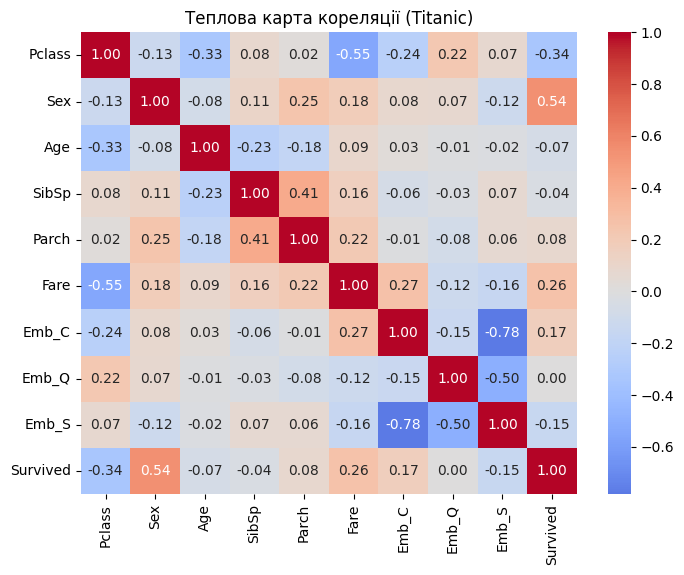

In [85]:
# Кореляція ознак з виживанням і баланс класів
print(data_t.corr()['Survived'].drop('Survived').sort_values(key=abs, ascending=False))
print('\nЧастка тих, хто вижив:', round(data_t['Survived'].mean() * 100, 1), '%')

plt.figure(figsize=(8, 6))
sns.heatmap(data_t.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Теплова карта кореляції (Titanic)')
plt.show()

## 2. Три класифікатори і підбір параметрів

Для різноманітності використано два оптимізатори:
- **GridSearchCV** (повний перебір сітки) — для логістичної регресії та методу опорних векторів;
- **RandomizedSearchCV** (40 випадкових комбінацій) — для випадкового лісу, у якого сітка параметрів велика.

In [86]:
# Підготовка даних Титаніка (повністю, від читання файлу) і поділ на вибірки
import glob
fname = sorted(glob.glob('*titanic*.csv'))[0]
titanic = pd.read_csv(fname)
titanic['Age'] = titanic['Age'].fillna(titanic['Age'].mean())
titanic['Embarked'] = titanic['Embarked'].fillna(titanic['Embarked'].mode()[0])
titanic = titanic.drop(columns='Cabin').drop_duplicates()
titanic['Sex'] = titanic['Sex'].map({'male': 0, 'female': 1})
titanic = pd.get_dummies(titanic, columns=['Embarked'], prefix='Emb', dtype=int)
features_t = ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Emb_C', 'Emb_Q', 'Emb_S']
data_t = titanic[features_t + ['Survived']]

X_t = data_t[features_t]
y_t = data_t['Survived']
X_tr_t, X_te_t, y_tr_t, y_te_t = train_test_split(
    X_t, y_t, test_size=0.2, stratify=y_t, random_state=RANDOM_STATE)
print('Навчальний набір:', X_tr_t.shape, ' Тестовий набір:', X_te_t.shape)

searches_t = {
    'Логістична регресія': GridSearchCV(
        make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, solver='liblinear')),
        {'logisticregression__C': [0.01, 0.1, 1, 10, 100],
         'logisticregression__penalty': ['l1', 'l2']},
        cv=cv5, scoring='accuracy', n_jobs=-1),
    'SVM (SVC)': GridSearchCV(
        make_pipeline(StandardScaler(), SVC(probability=True, random_state=RANDOM_STATE)),
        {'svc__kernel': ['linear', 'rbf'], 'svc__C': [0.1, 1, 10], 'svc__gamma': ['scale', 0.01, 0.1]},
        cv=cv5, scoring='accuracy', n_jobs=-1),
    'Випадковий ліс': RandomizedSearchCV(
        RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
        {'n_estimators': [100, 200, 300], 'max_depth': [3, 5, 7, 10, None],
         'min_samples_leaf': [1, 2, 4, 8], 'max_features': ['sqrt', 'log2', None]},
        n_iter=40, cv=cv5, scoring='accuracy', random_state=RANDOM_STATE, n_jobs=-1),
}
for name, s in searches_t.items():
    s.fit(X_tr_t, y_tr_t)
    print(f'{name}:\n   найкращі параметри: {s.best_params_}\n   accuracy на крос-валідації: {s.best_score_:.4f}')

Навчальний набір: (712, 9)  Тестовий набір: (179, 9)
Логістична регресія:
   найкращі параметри: {'logisticregression__C': 1, 'logisticregression__penalty': 'l2'}
   accuracy на крос-валідації: 0.8020
SVM (SVC):
   найкращі параметри: {'svc__C': 1, 'svc__gamma': 'scale', 'svc__kernel': 'rbf'}
   accuracy на крос-валідації: 0.8189
Випадковий ліс:
   найкращі параметри: {'n_estimators': 200, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': 10}
   accuracy на крос-валідації: 0.8203


## 3. Оцінка моделей і вибір найкращої

Логістична регресія: accuracy = 0.7933
              precision    recall  f1-score   support

 Загинув (0)      0.817     0.855     0.836       110
   Вижив (1)      0.750     0.696     0.722        69

    accuracy                          0.793       179
   macro avg      0.784     0.775     0.779       179
weighted avg      0.791     0.793     0.792       179

SVM (SVC): accuracy = 0.8324
              precision    recall  f1-score   support

 Загинув (0)      0.845     0.891     0.867       110
   Вижив (1)      0.810     0.739     0.773        69

    accuracy                          0.832       179
   macro avg      0.827     0.815     0.820       179
weighted avg      0.831     0.832     0.831       179

Випадковий ліс: accuracy = 0.8380
              precision    recall  f1-score   support

 Загинув (0)      0.858     0.882     0.870       110
   Вижив (1)      0.803     0.768     0.785        69

    accuracy                          0.838       179
   macro avg      0.831   

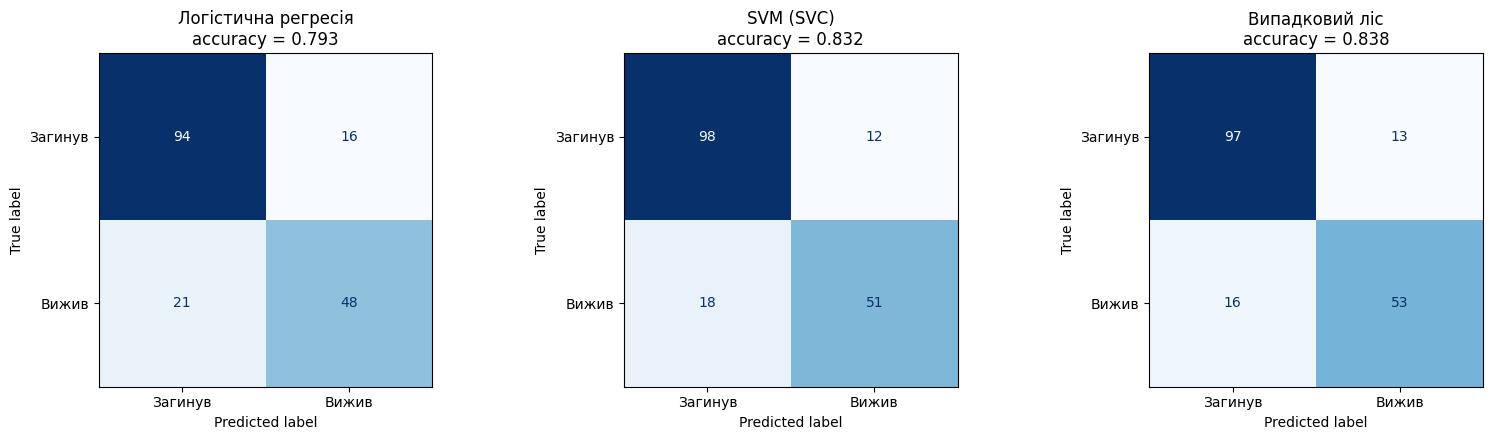

,Accuracy,Precision,Recall,F1,CV_accuracy
Випадковий ліс,0.838,0.803,0.768,0.785,0.820
SVM (SVC),0.832,0.810,0.739,0.773,0.819
Логістична регресія,0.793,0.750,0.696,0.722,0.802


Найкраща модель: Випадковий ліс (accuracy = 0.8380, F1 = 0.7852)


In [87]:
preds_t = {name: s.best_estimator_.predict(X_te_t) for name, s in searches_t.items()}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (name, pred) in zip(axes, preds_t.items()):
    print('=' * 60)
    print(f'{name}: accuracy = {accuracy_score(y_te_t, pred):.4f}')
    print(classification_report(y_te_t, pred, target_names=['Загинув (0)', 'Вижив (1)'], digits=3))
    ConfusionMatrixDisplay(confusion_matrix(y_te_t, pred), display_labels=['Загинув', 'Вижив']).plot(
        ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f'{name}\naccuracy = {accuracy_score(y_te_t, pred):.3f}')
plt.tight_layout(); plt.show()

res_t = pd.DataFrame({
    name: {'Accuracy': accuracy_score(y_te_t, p),
           'Precision': precision_score(y_te_t, p),
           'Recall': recall_score(y_te_t, p),
           'F1': f1_score(y_te_t, p),
           'CV_accuracy': searches_t[name].best_score_}
    for name, p in preds_t.items()}).T.sort_values(['Accuracy', 'CV_accuracy'], ascending=False)
display(res_t)

best_name_t = res_t.index[0]
best_t = searches_t[best_name_t].best_estimator_
print(f"Найкраща модель: {best_name_t} (accuracy = {res_t.loc[best_name_t, 'Accuracy']:.4f}, "
      f"F1 = {res_t.loc[best_name_t, 'F1']:.4f})")

,Важливість (випадковий ліс),Коефіцієнт (логістична регресія)
Sex,0.308,1.307
Fare,0.256,0.186
Age,0.204,-0.460
Pclass,0.099,-0.784
SibSp,0.054,-0.329
Parch,0.041,-0.112
Emb_C,0.017,0.089
Emb_S,0.013,-0.059
Emb_Q,0.007,-0.031


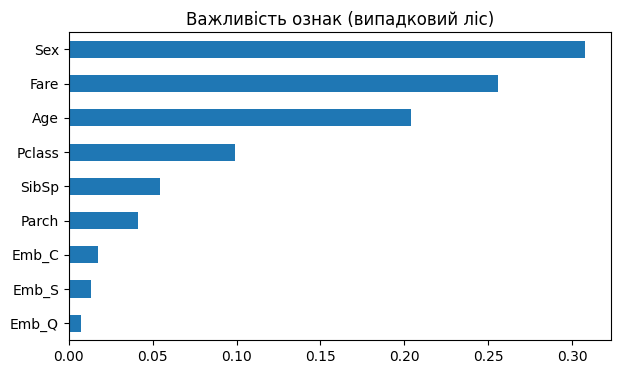

In [88]:
# Характеристики найкращої моделі: які ознаки найважливіші
rf_t = searches_t['Випадковий ліс'].best_estimator_
lr_t = searches_t['Логістична регресія'].best_estimator_[-1]
imp = pd.DataFrame({
    'Важливість (випадковий ліс)': rf_t.feature_importances_,
    'Коефіцієнт (логістична регресія)': lr_t.coef_[0],
}, index=features_t).sort_values('Важливість (випадковий ліс)', ascending=False)
display(imp)

imp['Важливість (випадковий ліс)'].sort_values().plot.barh(figsize=(7, 4), title='Важливість ознак (випадковий ліс)')
plt.show()

## 4. Прогноз для 10 випадків

In [89]:
# 10 випадкових пасажирів з тестової вибірки (модель їх не бачила під час навчання)
sample = X_te_t.sample(10, random_state=RANDOM_STATE)
forecast = titanic.loc[sample.index, ['PassengerId', 'Name', 'Pclass', 'Sex', 'Age', 'Fare']].copy()
forecast['Sex'] = forecast['Sex'].map({0: 'male', 1: 'female'})
forecast['Age'] = forecast['Age'].round(1)
forecast['P(вижив)'] = best_t.predict_proba(sample)[:, 1].round(3)
forecast['Прогноз'] = np.where(best_t.predict(sample) == 1, 'Вижив', 'Загинув')
forecast['Насправді'] = np.where(y_te_t.loc[sample.index] == 1, 'Вижив', 'Загинув')
forecast['Вірно'] = np.where(forecast['Прогноз'] == forecast['Насправді'], '✓', '✗')
print(f'Прогноз моделі "{best_name_t}" для 10 пасажирів:')
display(forecast.reset_index(drop=True))
print(f"Вірних прогнозів: {(forecast['Вірно'] == '✓').sum()} з 10")

Прогноз моделі "Випадковий ліс" для 10 пасажирів:


,PassengerId,Name,Pclass,Sex,Age,Fare,P(вижив),Прогноз,Насправді,Вірно
0,379,"Betros, Mr. Tannous",3,male,20.000,4.013,0.598,Вижив,Загинув,✗
1,479,"Karlsson, Mr. Nils August",3,male,22.000,7.521,0.071,Загинув,Загинув,✓
2,139,"Osen, Mr. Olaf Elon",3,male,16.000,9.217,0.148,Загинув,Загинув,✓
3,715,"Greenberg, Mr. Samuel",2,male,52.000,13.000,0.084,Загинув,Загинув,✓
4,326,"Young, Miss. Marie Grice",1,female,36.000,135.633,0.995,Вижив,Вижив,✓
5,636,"Davis, Miss. Mary",2,female,28.000,13.000,0.922,Вижив,Вижив,✓
6,81,"Waelens, Mr. Achille",3,male,22.000,9.000,0.083,Загинув,Загинув,✓
7,571,"Harris, Mr. George",2,male,62.000,10.500,0.031,Загинув,Вижив,✗
8,630,"O'Connell, Mr. Patrick D",3,male,29.700,7.733,0.031,Загинув,Загинув,✓
9,672,"Davidson, Mr. Thornton",1,male,31.000,52.000,0.407,Загинув,Загинув,✓


Вірних прогнозів: 8 з 10


### Висновок до завдання 2

Датасет Титаніка (891 пасажир) підготовлено так само, як у ЛР 2. Пропущений вік (177 значень) замінено середнім, порт посадки (2 пропуски) — найчастішим значенням. Стовпець Cabin, у якому 77 % пропусків, видалено. Дублікатів немає. Стать закодовано як 0/1, а порт посадки — методом one-hot, тобто трьома стовпцями `Emb_C`, `Emb_Q` і `Emb_S`. Ідентифікатори (PassengerId, Name, Ticket) не використовувалися. Модель навчалася на 9 ознаках. Найсильніше з виживанням корелюють стать (r = 0,54), клас (r = −0,34) та вартість квитка (r = 0,26). Вижили 38,4 % пасажирів, тому поділ на вибірки (712 / 179) виконано зі стратифікацією.

Побудовано три класифікатори з двома різними оптимізаторами. Для логістичної регресії та методу опорних векторів використано GridSearchCV. Найкращі параметри: для логістичної регресії C = 1, L2; для SVC ядро rbf, C = 1. Для випадкового лісу використано RandomizedSearchCV з 40 випадковими комбінаціями. Найкращий варіант: 200 дерев, глибина 10, max_features = log2.

Результати на тестовій вибірці:
- випадковий ліс — accuracy 0,838, F1 = 0,785;
- SVC — accuracy 0,832, F1 = 0,773;
- логістична регресія — accuracy 0,793, F1 = 0,722.

На крос-валідації порядок моделей той самий, тому найкращою обрано випадковий ліс. Нелінійні моделі (ліс і SVC з rbf-ядром) на 4 % точніші за логістичну регресію, бо враховують взаємодію ознак. Наприклад, шанси жінки з 1-го класу і жінки з 3-го класу суттєво різняться (див. ЛР 2). Клас «вижив» модель розпізнає гірше, ніж клас «загинув»: recall становить 0,77 проти 0,88. Отже, приблизно чверть тих, хто вижив, модель вважає загиблими.

Найважливіші ознаки для випадкового лісу — стать (0,31), вартість квитка (0,26), вік (0,20) та клас (0,10). Це узгоджується з висновками ЛР 2. Для 10 випадкових пасажирів з тестової вибірки модель дала 8 правильних прогнозів. Помилки припали на нетипові випадки: 20-річному чоловікові з 3-го класу з дуже дешевим квитком модель передбачила виживання (імовірність 0,60), а 62-річний чоловік з 2-го класу вижив, хоча модель оцінила його шанси лише у 3 %. Точність близько 84 % — добрий результат для цих даних, адже порятунок залежав і від випадкових обставин, яких немає в датасеті.